# Analytical Part

This notebook consolidates the cleaned BLE supply balance data and derived indicators for barley, potatoes and soft wheat. The objective is to prepare a validated analytical dataset for examining agricultural market resilience in Germany from 1991/92 to 2024/25.

In [8]:
# Load the processed BLE dataset and derived indicators

from pathlib import Path
import pandas as pd

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"

# Load the main dataset
df_analysis = pd.read_excel(
    processed_dir / "ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx"
)

# Load derived indicators
net_trade_balance = pd.read_excel(
    processed_dir / "ble_net_trade_balance_1991-2025.xlsx"
)

production_change = pd.read_excel(
    processed_dir / "ble_production_change_1991-2025.xlsx"
)

domestic_use_change = pd.read_excel(
    processed_dir / "ble_domestic_use_change_1991-2025.xlsx"
)

# Check dataset dimensions
print("Main dataset:", df_analysis.shape)
print("Net trade balance:", net_trade_balance.shape)
print("Production changes:", production_change.shape)
print("Domestic use changes:", domestic_use_change.shape)


Main dataset: (1836, 6)
Net trade balance: (102, 5)
Production changes: (102, 5)
Domestic use changes: (102, 5)


## Preparation of the Analytical Dataset

This section extracts the key supply balance indicators and combines them with the derived metrics to create a consolidated dataset for further analysis.

In [9]:

# Extract key supply balance indicators

key_positions = [
    "Einfuhr",
    "Ausfuhr",
    "Inlandsverwendung insgesamt",
    "Inlandsverwendung",
    "Verwendbare Erzeugung",
    "Selbstversorgungsgrad in %",
]

key_data = df_analysis.loc[
    df_analysis["Bilanz Position"].isin(key_positions),
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Bilanz Position",
        "Bilanz Wert",
    ],
].copy()

print("Extracted records:", key_data.shape[0])
print("Products:", sorted(key_data["Bilanz Produkt"].unique()))
print("Balance positions:", sorted(key_data["Bilanz Position"].unique()))


Extracted records: 510
Products: ['Gerste', 'Kartoffeln', 'Weichweizen']
Balance positions: ['Ausfuhr', 'Einfuhr', 'Inlandsverwendung', 'Inlandsverwendung insgesamt', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung']


### Reshape Supply Balance Indicators

The selected supply balance positions are reshaped into separate columns for each indicator, with one record per product and financial year.

In [10]:

# Reshape supply balance indicators into a wide format

supply_wide = key_data.pivot(
    index=["Wirtschaftsjahr", "Bilanz Produkt"],
    columns="Bilanz Position",
    values="Bilanz Wert",
).reset_index()

supply_wide.columns.name = None

print("Supply balance dataset shape:", supply_wide.shape)
print("Duplicate product-year records:",
      supply_wide.duplicated(
          subset=["Wirtschaftsjahr", "Bilanz Produkt"]
      ).sum())

display(supply_wide.head(10))


Supply balance dataset shape: (102, 8)
Duplicate product-year records: 0


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Inlandsverwendung,Inlandsverwendung insgesamt,Selbstversorgungsgrad in %,Verwendbare Erzeugung
0,1991/92,Gerste,3537.0,1233.0,NaN,10637.0,136.26022,14494.0
1,1991/92,Kartoffeln,1002.0,1757.0,10787.0,NaN,90.00000,9737.0
2,1991/92,Weichweizen,4941.0,1440.0,NaN,11639.0,142.03110,16531.0
3,1992/93,Gerste,2725.0,1035.0,NaN,10502.0,116.13026,12196.0
4,1992/93,Kartoffeln,1122.0,1458.0,10644.0,NaN,97.00000,10358.0
5,1992/93,Weichweizen,5457.0,1660.0,NaN,11004.0,140.60342,15472.0
6,1993/94,Gerste,3315.0,1154.0,NaN,9692.0,113.55757,11006.0
7,1993/94,Kartoffeln,1090.0,1320.0,11912.0,NaN,98.00000,11633.0
8,1993/94,Weichweizen,7802.0,1637.0,NaN,12943.0,121.45561,15720.0
9,1994/95,Gerste,3251.0,1223.0,NaN,9901.0,108.57489,10750.0


### Standardization Domestic Use

Domestic use is reported under different BLE position names for potatoes and the two cereal products. These values are consolidated into a single column while preserving the original wide-format dataset.

In [11]:

# Standardize domestic use across all products

supply_base = supply_wide.copy()

supply_base["Inlandsverwendung standardisiert"] = (
    supply_base["Inlandsverwendung insgesamt"]
    .combine_first(supply_base["Inlandsverwendung"])
)

# Check the standardized values
print("Missing standardized domestic use values:",
      supply_base["Inlandsverwendung standardisiert"].isna().sum())

print("\nDomestic use values by product:")
print(
    supply_base.groupby("Bilanz Produkt")[
        "Inlandsverwendung standardisiert"
    ].agg(["count", "min", "max"])
)

display(
    supply_base[
        [
            "Wirtschaftsjahr",
            "Bilanz Produkt",
            "Inlandsverwendung standardisiert",
        ]
    ].head(9)
)


Missing standardized domestic use values: 0

Domestic use values by product:
                count          min          max
Bilanz Produkt                                 
Gerste             34   7886.53224  10815.54467
Kartoffeln         34   6253.74502  12223.00000
Weichweizen        34  11004.00000  19760.14208


,Wirtschaftsjahr,Bilanz Produkt,Inlandsverwendung standardisiert
0,1991/92,Gerste,10637.0
1,1991/92,Kartoffeln,10787.0
2,1991/92,Weichweizen,11639.0
3,1992/93,Gerste,10502.0
4,1992/93,Kartoffeln,10644.0
5,1992/93,Weichweizen,11004.0
6,1993/94,Gerste,9692.0
7,1993/94,Kartoffeln,11912.0
8,1993/94,Weichweizen,12943.0


### Creation of the Standardized Supply Dataset

This section retains the key supply balance indicators and the standardized domestic use measure in a consistent structure for all three products.

In [12]:
# Create a standardized supply dataset

supply_base = supply_base.drop(
    columns=[
        "Inlandsverwendung",
        "Inlandsverwendung insgesamt",
    ]
)

print("Standardized supply dataset shape:", supply_base.shape)
print("Duplicate product-year records:",
      supply_base.duplicated(
          subset=["Wirtschaftsjahr", "Bilanz Produkt"]
      ).sum())

display(supply_base.head())

Standardized supply dataset shape: (102, 7)
Duplicate product-year records: 0


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0


In [13]:

# Merge the net trade balance into the analytical dataset

net_trade_merge = net_trade_balance[
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Nettohandelsbilanz",
    ]
].copy()

analytical_df = supply_base.merge(
    net_trade_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "Missing net trade balance values:",
    analytical_df["Nettohandelsbilanz"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("Analytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64
Missing net trade balance values: 0
Analytical dataset shape: (102, 8)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0


In [14]:

# Merge year-over-year production changes

production_merge = production_change[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Veränderung in %"]
].copy()

production_merge = production_merge.rename(
    columns={"Veränderung in %": "Erzeugungsänderung in %"}
)

analytical_df = analytical_df.merge(
    production_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "Missing production changes:",
    analytical_df["Erzeugungsänderung in %"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("Analytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64
Missing production changes: 3
Analytical dataset shape: (102, 9)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734


### Add Year-over-Year Changes in Domestic Use

This section adds the annual percentage change in domestic use for each product and financial year.

In [15]:

# Merge year-over-year changes in domestic use

domestic_use_merge = domestic_use_change[
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Veränderung in %",
    ]
].copy()

domestic_use_merge = domestic_use_merge.rename(
    columns={
        "Veränderung in %": "Inlandsverwendungsänderung in %"
    }
)

analytical_df = analytical_df.merge(
    domestic_use_merge,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("Merge results:")
print(analytical_df["_merge"].value_counts())

print(
    "\nMissing domestic use changes:",
    analytical_df["Inlandsverwendungsänderung in %"].isna().sum(),
)

analytical_df = analytical_df.drop(columns="_merge")

print("\nAnalytical dataset shape:", analytical_df.shape)
display(analytical_df.head())


Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64

Missing domestic use changes: 3

Analytical dataset shape: (102, 10)


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %,Inlandsverwendungsänderung in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN,NaN
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN,NaN
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN,NaN
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836,-1.269155
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734,-1.325670


In [16]:

# Check whether import and export quotas are available

print("Quota positions in df_analysis:")
print(
    df_analysis.loc[
        df_analysis["Bilanz Position"].isin(
            ["Importquote in %", "Exportquote in %"]
        ),
        "Bilanz Position",
    ].value_counts()
)

print("\nCurrent analytical dataset columns:")
print(analytical_df.columns.tolist())

print("\nCurrent analytical dataset shape:")
print(analytical_df.shape)


Quota positions in df_analysis:
Series([], Name: count, dtype: int64)

Current analytical dataset columns:
['Wirtschaftsjahr', 'Bilanz Produkt', 'Ausfuhr', 'Einfuhr', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung', 'Inlandsverwendung standardisiert', 'Nettohandelsbilanz', 'Erzeugungsänderung in %', 'Inlandsverwendungsänderung in %']

Current analytical dataset shape:
(102, 10)


### Load the Previously Calculated Quotas

The import and export quotas were calculated in the data preparation notebook and saved separately in the processed dataset. This section reloads that dataset to retrieve the quota indicators.

In [20]:

# Reload the processed dataset containing the calculated quotas

from pathlib import Path
import pandas as pd

project_dir = Path.cwd().parent
processed_dir = project_dir / "data" / "processed"

quota_source_path = (
    processed_dir
    / "ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx"
)

quota_source = pd.read_excel(quota_source_path)

print("Loaded file:", quota_source_path.name)
print("Dataset shape:", quota_source.shape)

print("\nAvailable quota positions:")
print(
    quota_source.loc[
        quota_source["Bilanz Position"].isin(
            ["Importquote", "Exportquote"]
        ),
        "Bilanz Position",
    ].value_counts()
)


Loaded file: ble_cleaned_supply_balance_with_quotas_1991-2025.xlsx
Dataset shape: (1836, 6)

Available quota positions:
Bilanz Position
Importquote    102
Exportquote    102
Name: count, dtype: int64


In [21]:

# Extract and reshape the import and export quotas

quota_data = quota_source.loc[
    quota_source["Bilanz Position"].isin(
        ["Importquote", "Exportquote"]
    ),
    [
        "Wirtschaftsjahr",
        "Bilanz Produkt",
        "Bilanz Position",
        "Bilanz Wert",
    ],
].copy()

quota_wide = quota_data.pivot(
    index=["Wirtschaftsjahr", "Bilanz Produkt"],
    columns="Bilanz Position",
    values="Bilanz Wert",
).reset_index()

quota_wide.columns.name = None

quota_wide = quota_wide.rename(
    columns={
        "Importquote": "Importquote in %",
        "Exportquote": "Exportquote in %",
    }
)

print("Quota dataset shape:", quota_wide.shape)
print("Missing import quotas:", quota_wide["Importquote in %"].isna().sum())
print("Missing export quotas:", quota_wide["Exportquote in %"].isna().sum())

# Merge the quotas into the analytical dataset

analytical_df = analytical_df.merge(
    quota_wide,
    on=["Wirtschaftsjahr", "Bilanz Produkt"],
    how="left",
    validate="one_to_one",
    indicator=True,
)

print("\nMerge results:")
print(analytical_df["_merge"].value_counts())

print("\nMissing import quotas:", analytical_df["Importquote in %"].isna().sum())
print("Missing export quotas:", analytical_df["Exportquote in %"].isna().sum())

analytical_df = analytical_df.drop(columns="_merge")

print("\nAnalytical dataset shape:", analytical_df.shape)
print("\nColumns:")
print(analytical_df.columns.tolist())

display(analytical_df.head())


Quota dataset shape: (102, 4)
Missing import quotas: 0
Missing export quotas: 0

Merge results:
_merge
both          102
left_only       0
right_only      0
Name: count, dtype: int64

Missing import quotas: 0
Missing export quotas: 0

Analytical dataset shape: (102, 12)

Columns:
['Wirtschaftsjahr', 'Bilanz Produkt', 'Ausfuhr', 'Einfuhr', 'Selbstversorgungsgrad in %', 'Verwendbare Erzeugung', 'Inlandsverwendung standardisiert', 'Nettohandelsbilanz', 'Erzeugungsänderung in %', 'Inlandsverwendungsänderung in %', 'Exportquote in %', 'Importquote in %']


,Wirtschaftsjahr,Bilanz Produkt,Ausfuhr,Einfuhr,Selbstversorgungsgrad in %,Verwendbare Erzeugung,Inlandsverwendung standardisiert,Nettohandelsbilanz,Erzeugungsänderung in %,Inlandsverwendungsänderung in %,Exportquote in %,Importquote in %
0,1991/92,Gerste,3537.0,1233.0,136.26022,14494.0,10637.0,2304.0,NaN,NaN,24.403201,11.591614
1,1991/92,Kartoffeln,1002.0,1757.0,90.00000,9737.0,10787.0,-755.0,NaN,NaN,10.290644,16.288125
2,1991/92,Weichweizen,4941.0,1440.0,142.03110,16531.0,11639.0,3501.0,NaN,NaN,29.889299,12.372197
3,1992/93,Gerste,2725.0,1035.0,116.13026,12196.0,10502.0,1690.0,-15.854836,-1.269155,22.343391,9.855266
4,1992/93,Kartoffeln,1122.0,1458.0,97.00000,10358.0,10644.0,-336.0,6.377734,-1.325670,10.832207,13.697858


### Final Data Quality Checks

This section validates the completeness and consistency of the consolidated analytical dataset. It checks duplicate product-year combinations, the number of observations per product, missing values and data types before the dataset is saved.

In [22]:

# Check the final analytical dataset

print("Dataset shape:", analytical_df.shape)

# Check duplicate product-year combinations
duplicate_count = analytical_df.duplicated(
    subset=["Wirtschaftsjahr", "Bilanz Produkt"]
).sum()

print("\nDuplicate product-year records:", duplicate_count)

# Check observations per product
print("\nRecords per product:")
print(analytical_df["Bilanz Produkt"].value_counts().sort_index())

# Check unique financial years
print("\nUnique financial years:", analytical_df["Wirtschaftsjahr"].nunique())

# Check missing values
print("\nMissing values per column:")
print(analytical_df.isna().sum())

# Check data types
print("\nData types:")
print(analytical_df.dtypes)

# Check whether all analytical indicator columns are numeric
numeric_columns = [
    "Ausfuhr",
    "Einfuhr",
    "Selbstversorgungsgrad in %",
    "Verwendbare Erzeugung",
    "Inlandsverwendung standardisiert",
    "Nettohandelsbilanz",
    "Erzeugungsänderung in %",
    "Inlandsverwendungsänderung in %",
    "Exportquote in %",
    "Importquote in %",
]

print("\nNon-numeric values in indicator columns:")
print(
    analytical_df[numeric_columns]
    .apply(lambda column: pd.to_numeric(column, errors="coerce").isna().sum())
)


Dataset shape: (102, 12)

Duplicate product-year records: 0

Records per product:
Bilanz Produkt
Gerste         34
Kartoffeln     34
Weichweizen    34
Name: count, dtype: int64

Unique financial years: 34

Missing values per column:
Wirtschaftsjahr                     0
Bilanz Produkt                      0
Ausfuhr                             0
Einfuhr                             0
Selbstversorgungsgrad in %          0
Verwendbare Erzeugung               0
Inlandsverwendung standardisiert    0
Nettohandelsbilanz                  0
Erzeugungsänderung in %             3
Inlandsverwendungsänderung in %     3
Exportquote in %                    0
Importquote in %                    0
dtype: int64

Data types:
Wirtschaftsjahr                         str
Bilanz Produkt                          str
Ausfuhr                             float64
Einfuhr                             float64
Selbstversorgungsgrad in %          float64
Verwendbare Erzeugung               float64
Inlandsverwendung sta

### Saving the Final Analytical Dataset

The consolidated analytical dataset has passed the main data quality checks. It is saved as an Excel file for use in the subsequent analysis and visualisation stages.

In [23]:

# Save the final analytical dataset

output_path = (
    processed_dir
    / "ble_supply_balance_with_derived_indicators_1991-2025.xlsx"
)

analytical_df.to_excel(output_path, index=False)

print("Analytical dataset saved successfully.")
print("File:", output_path)
print("Dataset shape:", analytical_df.shape)
print("Number of products:", analytical_df["Bilanz Produkt"].nunique())
print("Number of financial years:", analytical_df["Wirtschaftsjahr"].nunique())


Analytical dataset saved successfully.
File: c:\Users\incog\Desktop\Portfolio_Project_Agriculture\data\processed\ble_supply_balance_with_derived_indicators_1991-2025.xlsx
Dataset shape: (102, 12)
Number of products: 3
Number of financial years: 34


## Visualizations - Availability and Supply Balance

This section visualizes the development of agricultural supply in Germany for barley, potatoes and soft wheat from 1991/92 to 2024/25. The analysis focuses on usable production, net trade balance and self-sufficiency to compare supply patterns across the three products.

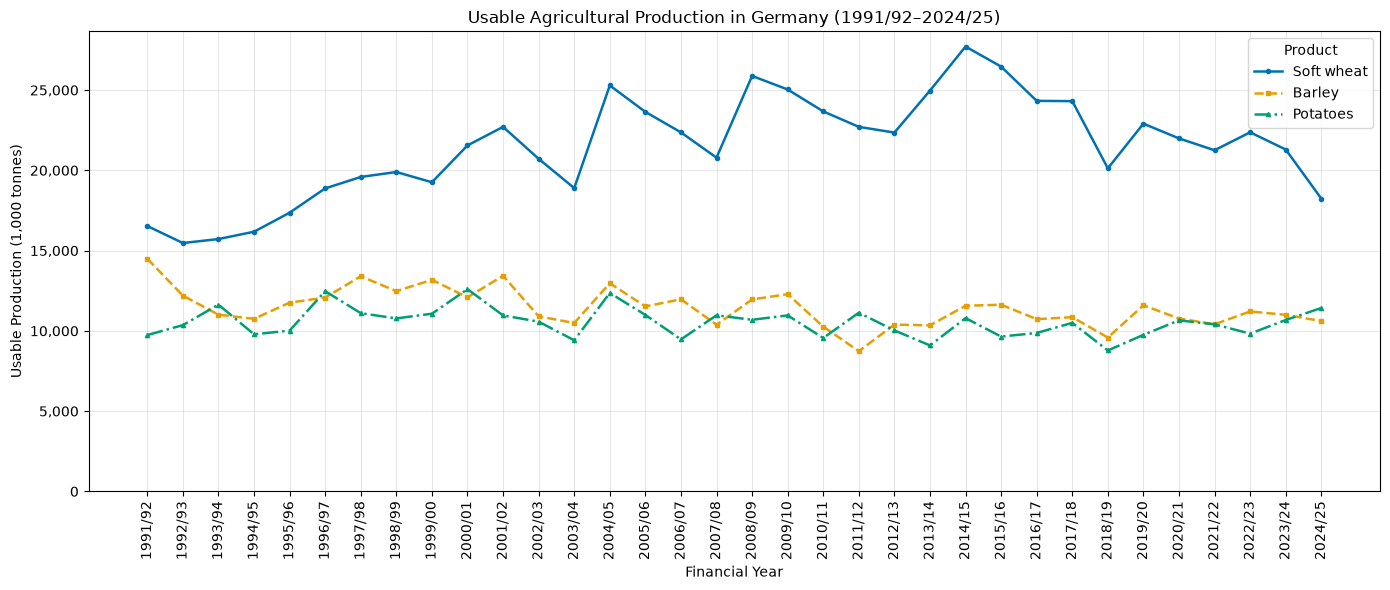

In [29]:

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select usable production data
production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Sort financial years chronologically
production_plot = production_plot.sort_values(
    by=["Bilanz Produkt", "Wirtschaftsjahr"]
)

# Define a colorblind-friendly color palette
product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
        "linestyle": "-",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
        "linestyle": "--",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-.",
    },
}

# Create the line chart
fig, ax = plt.subplots(figsize=(14, 6))

# Plot usable production for each product
for product, style in product_styles.items():
    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ]

    ax.plot(
        product_data["Wirtschaftsjahr"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle=style["linestyle"],
        markersize=3,
        linewidth=1.8,
    )

# Set chart title and axis labels
ax.set_title(
    "Usable Agricultural Production in Germany (1991/92–2024/25)"
)
ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production (1,000 tonnes)")

# Format the y-axis using English thousands separators
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Format x-axis labels
ax.tick_params(axis="x", labelrotation=90)

# Add legend and grid
ax.legend(title="Product")
ax.grid(True, alpha=0.3)

# Improve layout
fig.tight_layout()

# Display the chart
plt.show()


In [25]:
df_analysis.loc[
    df_analysis["Bilanz Position"] == "Verwendbare Erzeugung",
    ["Bilanz Produkt", "Bilanz Einheit"]
].drop_duplicates()

,Bilanz Produkt,Bilanz Einheit
15,Gerste,1 000 t Produktgewicht
590,Kartoffeln,1 000 t Produktgewicht
1069,Weichweizen,1 000 t Produktgewicht


In [26]:

# Compare usable production levels across products
production_plot.groupby("Bilanz Produkt")[
    "Verwendbare Erzeugung"
].agg(["min", "mean", "max"]).round(0)


,min,mean,max
Bilanz Produkt,,,
Gerste,8734.0,11442.0,14494.0
Kartoffeln,8778.0,10532.0,12598.0
Weichweizen,15472.0,21484.0,27711.0


In [30]:

# Define all historical events from the research timeline
historical_events = [
    {
        "start": 1990,
        "end": 1991,
        "label": "German reunification",
        "category": "Structural transition",
    },
    {
        "start": 1992,
        "end": 1992,
        "label": "CAP reform",
        "category": "Policy change",
    },
    {
        "start": 2003,
        "end": 2003,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2007,
        "end": 2008,
        "label": "Food-price crisis",
        "category": "Market shock",
    },
    {
        "start": 2018,
        "end": 2019,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2020,
        "end": 2021,
        "label": "COVID-19",
        "category": "Systemic and logistical shock",
    },
    {
        "start": 2021,
        "end": 2022,
        "label": "Energy and fertiliser shock",
        "category": "Input-cost shock",
    },
    {
        "start": 2022,
        "end": 2022,
        "label": "Invasion of Ukraine",
        "category": "Geopolitical shock",
    },
    {
        "start": 2022,
        "end": 2024,
        "label": "Inflation and food-price pressures",
        "category": "Macroeconomic development",
    },
    {
        "start": 2023,
        "end": 2024,
        "label": "Red Sea disruptions",
        "category": "Logistics shock",
    },
    {
        "start": 2026,
        "end": 2026,
        "label": "Middle East conflict",
        "category": "Ongoing geopolitical shock",
    },
]


### Visualize Usable Agricultural Production and Historical Events

This section visualizes usable production for barley, potatoes and soft wheat in Germany from 1991/92 to 2024/25. The three product series are displayed as solid, color-coded lines. Historical events are indicated by shaded background periods to provide context for potential production and market disruptions.

The event markers represent historical context and do not establish causal relationships. Calendar-year events are aligned approximately with the agricultural financial-year series.

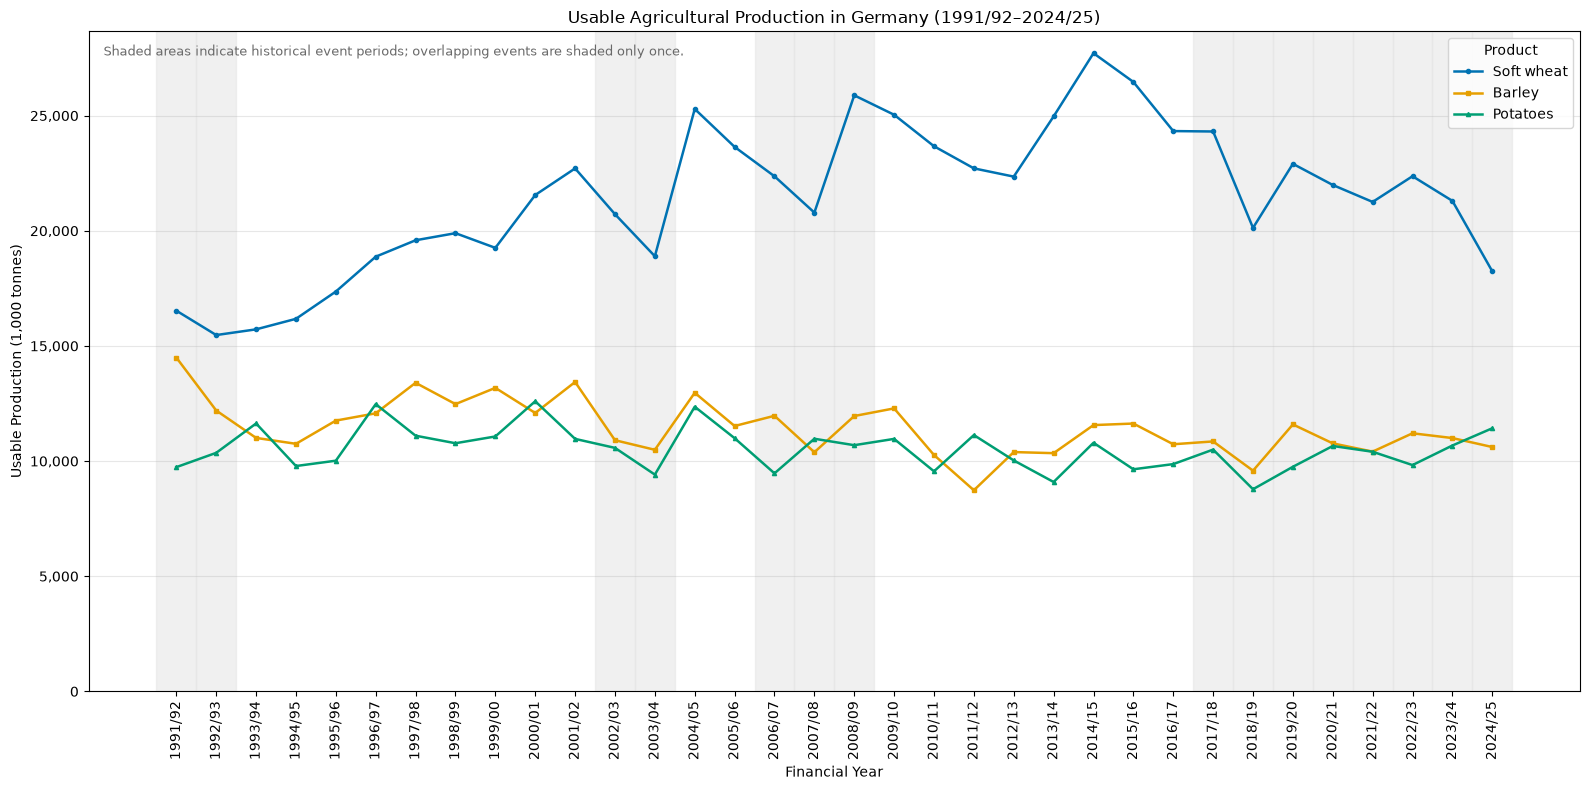

In [33]:

# Import visualization libraries
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select usable production data
production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Sort financial years chronologically
production_plot = production_plot.sort_values(
    by=["Bilanz Produkt", "Wirtschaftsjahr"]
)

# Define a colorblind-friendly color palette and line styles
product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
    },
}

# Define all historical events and their approximate calendar-year periods
historical_events = [
    {
        "start": 1990,
        "end": 1991,
        "label": "German reunification",
        "category": "Structural transition",
    },
    {
        "start": 1992,
        "end": 1992,
        "label": "CAP reform",
        "category": "Policy change",
    },
    {
        "start": 2003,
        "end": 2003,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2007,
        "end": 2008,
        "label": "Food-price crisis",
        "category": "Market shock",
    },
    {
        "start": 2018,
        "end": 2019,
        "label": "Drought and heat",
        "category": "Production shock",
    },
    {
        "start": 2020,
        "end": 2021,
        "label": "COVID-19",
        "category": "Systemic and logistical shock",
    },
    {
        "start": 2021,
        "end": 2022,
        "label": "Energy and fertiliser shock",
        "category": "Input-cost shock",
    },
    {
        "start": 2022,
        "end": 2022,
        "label": "Russia's invasion of Ukraine",
        "category": "Geopolitical shock",
    },
    {
        "start": 2022,
        "end": 2024,
        "label": "Inflation and food-price pressures",
        "category": "Macroeconomic development",
    },
    {
        "start": 2023,
        "end": 2024,
        "label": "Red Sea shipping disruptions",
        "category": "Logistics shock",
    },
    {
        "start": 2026,
        "end": 2026,
        "label": "Middle East conflict",
        "category": "Ongoing geopolitical shock",
    },
]

# Extract unique financial years in chronological order
years = sorted(
    production_plot["Wirtschaftsjahr"].dropna().unique(),
    key=lambda year: int(str(year)[:4]),
)

# Create a mapping from financial years to numeric plotting positions
year_positions = {
    year: position
    for position, year in enumerate(years)
}

# Define one consistent style for all historical event periods
event_color = "#E5E5E5"
event_alpha = 0.55

# Identify financial years overlapping with historical events
shaded_positions = set()

for event in historical_events:
    for position, year in enumerate(years):
        financial_year_start = int(str(year)[:4])
        financial_year_end = financial_year_start + 1

        # Check whether the financial year overlaps with the event
        if (
            financial_year_start <= event["end"]
            and financial_year_end >= event["start"]
        ):
            shaded_positions.add(position)

# Create the line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Draw each overlapping financial year only once
for position in sorted(shaded_positions):
    ax.axvspan(
        position - 0.5,
        position + 0.5,
        color=event_color,
        alpha=event_alpha,
        zorder=0,
    )

# Plot usable production for each agricultural product
for product, style in product_styles.items():
    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].copy()

    # Convert financial-year labels into numeric plotting positions
    product_data["Year position"] = (
        product_data["Wirtschaftsjahr"].map(year_positions)
    )

    # Sort observations by financial year
    product_data = product_data.sort_values("Year position")

    # Draw a solid, color-coded line for each product
    ax.plot(
        product_data["Year position"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle="-",
        linewidth=1.8,
        markersize=3,
        zorder=3,
    )

# Set the chart title and axis labels
ax.set_title(
    "Usable Agricultural Production in Germany (1991/92–2024/25)"
)
ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production (1,000 tonnes)")

# Format the y-axis with English thousands separators
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Display financial years on the x-axis
ax.set_xticks(range(len(years)))
ax.set_xticklabels(years, rotation=90)

# Add a legend identifying the agricultural products
ax.legend(title="Product")

# Add horizontal gridlines for easier comparisons
ax.grid(axis="y", alpha=0.3)

# Add a note explaining the historical event shading
ax.text(
    0.01,
    0.98,
    "Shaded areas indicate historical event periods; "
    "overlapping events are shaded only once.",
    transform=ax.transAxes,
    va="top",
    fontsize=9,
    color="dimgray",
)

# Adjust spacing to prevent labels from being cut off
fig.tight_layout()

# Display the chart
plt.show()


### Methodological Note: Historical Event Alignment

Historical events are recorded by calendar year, whereas the BLE dataset uses agricultural financial years. The alignment of historical events with the production data is therefore approximate. Shaded periods provide historical context and should not be interpreted as exact matches or as evidence of causal relationships between individual events and production changes.

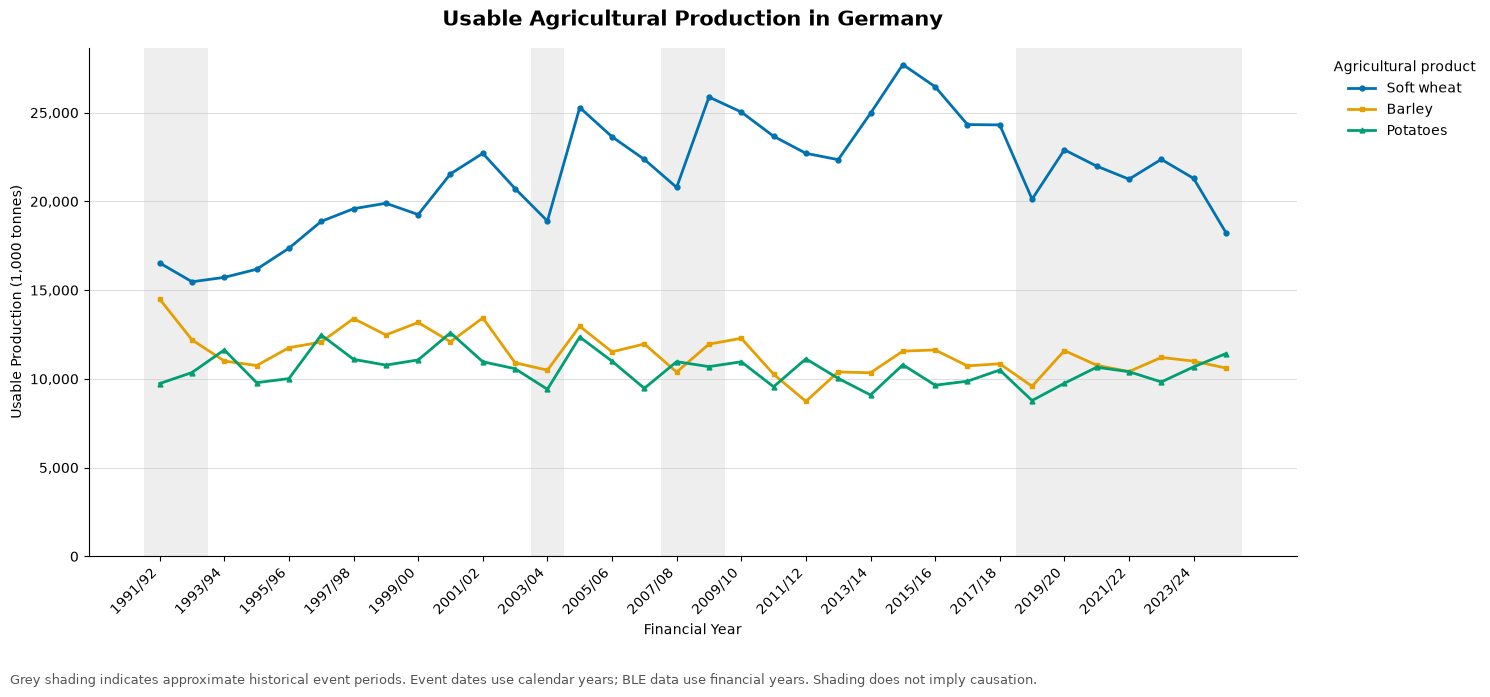

In [38]:

# Import visualization libraries
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Select and prepare usable production data
production_plot = analytical_df[
    ["Wirtschaftsjahr", "Bilanz Produkt", "Verwendbare Erzeugung"]
].copy()

# Extract the starting year of each financial year
production_plot["Startjahr"] = production_plot[
    "Wirtschaftsjahr"
].astype(str).str[:4].astype(int)

# Sort the data chronologically for each product
production_plot = production_plot.sort_values(
    ["Bilanz Produkt", "Startjahr"]
)

# Define product labels, colors and markers
product_styles = {
    "Weichweizen": {
        "label": "Soft wheat",
        "color": "#0072B2",
        "marker": "o",
    },
    "Gerste": {
        "label": "Barley",
        "color": "#E69F00",
        "marker": "s",
    },
    "Kartoffeln": {
        "label": "Potatoes",
        "color": "#009E73",
        "marker": "^",
    },
}

# Define the historical events from the reference table
historical_events = [
    {"start": 1990, "end": 1991, "label": "German reunification"},
    {"start": 1992, "end": 1992, "label": "CAP reform"},
    {"start": 2003, "end": 2003, "label": "Drought and heat"},
    {"start": 2007, "end": 2008, "label": "Global food-price crisis"},
    {"start": 2018, "end": 2019, "label": "Drought and heat"},
    {"start": 2020, "end": 2021, "label": "COVID-19 pandemic"},
    {"start": 2021, "end": 2022, "label": "Energy and fertiliser shock"},
    {"start": 2022, "end": 2022, "label": "Russia's invasion of Ukraine"},
    {"start": 2022, "end": 2024, "label": "Inflation and food-price pressures"},
    {"start": 2023, "end": 2024, "label": "Red Sea shipping disruptions"},
    {"start": 2026, "end": 2026, "label": "Middle East conflict"},
]

# Extract unique financial years and create plotting positions
year_table = (
    production_plot[["Wirtschaftsjahr", "Startjahr"]]
    .drop_duplicates()
    .sort_values("Startjahr")
)

years = year_table["Wirtschaftsjahr"].tolist()
start_years = year_table["Startjahr"].tolist()

year_positions = {
    year: position
    for position, year in enumerate(years)
}

# Define one uniform, light-grey style for historical periods
event_color = "#E5E5E5"
event_alpha = 0.65

# Identify each financial year to shade only once
shaded_positions = set()

for event in historical_events:
    for position, start_year in enumerate(start_years):

        # Approximate event alignment using the financial-year start year
        if event["start"] <= start_year <= event["end"]:
            shaded_positions.add(position)

# Create the figure and plotting area
fig, ax = plt.subplots(figsize=(15, 7))

# Draw uniform background shading for historical event periods
for position in sorted(shaded_positions):
    ax.axvspan(
        position - 0.5,
        position + 0.5,
        color=event_color,
        alpha=event_alpha,
        linewidth=0,
        zorder=0,
    )

# Plot usable production for each agricultural product
for product, style in product_styles.items():
    product_data = production_plot[
        production_plot["Bilanz Produkt"] == product
    ].copy()

    # Map financial years to chronological plotting positions
    product_data["Position"] = product_data[
        "Wirtschaftsjahr"
    ].map(year_positions)

    product_data = product_data.sort_values("Position")

    # Draw a solid line with a distinct color and marker
    ax.plot(
        product_data["Position"],
        product_data["Verwendbare Erzeugung"],
        label=style["label"],
        color=style["color"],
        marker=style["marker"],
        linestyle="-",
        linewidth=2,
        markersize=3.5,
        zorder=3,
    )

# Set the chart title and axis labels
ax.set_title(
    "Usable Agricultural Production in Germany",
    fontsize=15,
    fontweight="bold",
    loc="center",
    pad=16,
)

ax.set_xlabel("Financial Year")
ax.set_ylabel("Usable Production (1,000 tonnes)")

# Format the y-axis with English thousands separators
ax.yaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

# Start the y-axis at zero
ax.set_ylim(bottom=0)

# Show every second financial year to reduce label clutter
tick_positions = list(range(0, len(years), 2))

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    [years[position] for position in tick_positions],
    rotation=45,
    ha="right",
)

# Place gridlines behind the data
ax.set_axisbelow(True)
ax.grid(
    axis="y",
    color="#BDBDBD",
    linewidth=0.7,
    alpha=0.5,
)

# Add a clean legend to the right of the plot without a surrounding frame
ax.legend(
    title="Agricultural product",
    frameon=False,
    ncol=1,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
)

# Remove unnecessary chart borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add a methodological note below the chart
fig.text(
    0.01,
    0.015,
    "Grey shading indicates approximate historical event periods. "
    "Event dates use calendar years; BLE data use financial years. "
    "Shading does not imply causation.",
    fontsize=9,
    color="#555555",
)

# Adjust the layout to leave room for labels and the note
fig.tight_layout(rect=[0, 0.06, 1, 1])

# Display the final visualization
plt.show()


**Note:** The 2026 event is retained in the historical event list but is not shaded because it falls outside the observed data period (1991/92–2024/25). The alignment of historical events with agricultural financial years is approximate, as event dates are recorded by calendar year.